In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [2]:
print("Reading data")
data_dir = Path.cwd().parent / "data" / "processed" / "fraud_data.parquet"
df = pd.read_parquet(data_dir)

assert not df.empty
assert df.columns.is_unique
# primary key quality check
assert df['TransactionID'].is_unique
assert df['TransactionID'].notna().all()

# target quality check
assert df['isFraud'].notna().all()
assert set(df['isFraud'].unique()) <= {0, 1}

Reading data


In [3]:
df.select_dtypes(include='object').columns

Index(['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1',
       'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15',
       'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33',
       'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType',
       'DeviceInfo'],
      dtype='object')

In [4]:
# Find which colums have nulls
df.columns[df.isnull().any()].to_list()

['card2',
 'card3',
 'card4',
 'card5',
 'card6',
 'addr1',
 'addr2',
 'dist1',
 'dist2',
 'P_emaildomain',
 'R_emaildomain',
 'D1',
 'D2',
 'D3',
 'D4',
 'D5',
 'D6',
 'D7',
 'D8',
 'D9',
 'D10',
 'D11',
 'D12',
 'D13',
 'D14',
 'D15',
 'M1',
 'M2',
 'M3',
 'M4',
 'M5',
 'M6',
 'M7',
 'M8',
 'M9',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'V29',
 'V30',
 'V31',
 'V32',
 'V33',
 'V34',
 'V35',
 'V36',
 'V37',
 'V38',
 'V39',
 'V40',
 'V41',
 'V42',
 'V43',
 'V44',
 'V45',
 'V46',
 'V47',
 'V48',
 'V49',
 'V50',
 'V51',
 'V52',
 'V53',
 'V54',
 'V55',
 'V56',
 'V57',
 'V58',
 'V59',
 'V60',
 'V61',
 'V62',
 'V63',
 'V64',
 'V65',
 'V66',
 'V67',
 'V68',
 'V69',
 'V70',
 'V71',
 'V72',
 'V73',
 'V74',
 'V75',
 'V76',
 'V77',
 'V78',
 'V79',
 'V80',
 'V81',
 'V82',
 'V83',
 'V84',
 'V85',
 'V86',
 'V87',
 'V88',
 'V89

In [5]:
df.describe()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,...,id_17,id_18,id_19,id_20,id_21,id_22,id_24,id_25,id_26,id_32
count,5.905400e+05,590540.000000,5.905400e+05,590540.000000,590540.000000,581607.000000,588975.000000,586281.000000,524834.000000,524834.000000,...,139369.000000,45113.000000,139318.000000,139261.000000,5159.000000,5169.000000,4747.000000,5132.000000,5163.000000,77586.000000
mean,3.282270e+06,0.034990,7.372311e+06,135.027176,9898.734658,362.555488,153.194925,199.278897,290.733794,86.800630,...,189.451377,14.237337,353.128174,403.882666,368.269820,16.002708,12.800927,329.608924,149.070308,26.508597
std,1.704744e+05,0.183755,4.617224e+06,239.162522,4901.170153,157.793246,11.336444,41.244453,101.741072,2.690623,...,30.375360,1.561302,141.095343,152.160327,198.847038,6.897665,2.372447,97.461089,32.101995,3.737502
min,2.987000e+06,0.000000,8.640000e+04,0.251000,1000.000000,100.000000,100.000000,100.000000,100.000000,10.000000,...,100.000000,10.000000,100.000000,100.000000,100.000000,10.000000,11.000000,100.000000,100.000000,0.000000
25%,3.134635e+06,0.000000,3.027058e+06,43.321000,6019.000000,214.000000,150.000000,166.000000,204.000000,87.000000,...,166.000000,13.000000,266.000000,256.000000,252.000000,14.000000,11.000000,321.000000,119.000000,24.000000
50%,3.282270e+06,0.000000,7.306528e+06,68.769000,9678.000000,361.000000,150.000000,226.000000,299.000000,87.000000,...,166.000000,15.000000,341.000000,472.000000,252.000000,14.000000,11.000000,321.000000,149.000000,24.000000
75%,3.429904e+06,0.000000,1.124662e+07,125.000000,14184.000000,512.000000,150.000000,226.000000,330.000000,87.000000,...,225.000000,15.000000,427.000000,533.000000,486.500000,14.000000,15.000000,371.000000,169.000000,32.000000
max,3.577539e+06,1.000000,1.581113e+07,31937.391000,18396.000000,600.000000,231.000000,237.000000,540.000000,102.000000,...,229.000000,29.000000,671.000000,661.000000,854.000000,44.000000,26.000000,548.000000,216.000000,32.000000


In [6]:
# observe rates of null in data
sorted_missing_rates = df.isnull().mean().rename("null_rate").to_frame().sort_values(by="null_rate", ascending=False)
sorted_missing_rates.head(30)

,null_rate
id_24,0.991962
id_25,0.991310
id_07,0.991271
id_08,0.991271
id_21,0.991264
id_26,0.991257
id_27,0.991247
id_23,0.991247
id_22,0.991247
dist2,0.936284


In [7]:
print(f"Num Rows with >50% Nulls: {(sorted_missing_rates['null_rate'] > 0.5).sum()}")
print(f"Num Rows with >90% Nulls: {(sorted_missing_rates['null_rate'] > 0.9).sum()}")

Num Rows with >50% Nulls: 214
Num Rows with >90% Nulls: 12


## Observe rates over time

In [20]:
# get a column by assigning each row to a week
seconds_per_week = 60 * 60 * 24 * 7
df_with_time = df.assign(week=(df["TransactionDT"] // seconds_per_week).astype(int))

# calculate aggregate stats over grouped rows by their assigned week
weekly_stats = df_with_time.groupby('week', as_index=False).agg(
    num_transactions=("TransactionID", "sum"),
    average_transaction_amount=("TransactionAmt", "mean"),
    fraud_rate=("isFraud", "mean"),
    fraud_count=("isFraud", "sum")
)

weekly_stats.head()

,week,num_transactions,average_transaction_amount,fraud_rate,fraud_count
0,0,71403916145,129.360548,0.028055,668
1,1,84096039933,127.708545,0.026148,727
2,2,105335063325,131.417521,0.025500,879
3,3,115169214708,120.702856,0.018523,690
4,4,75064512514,133.615310,0.038226,919


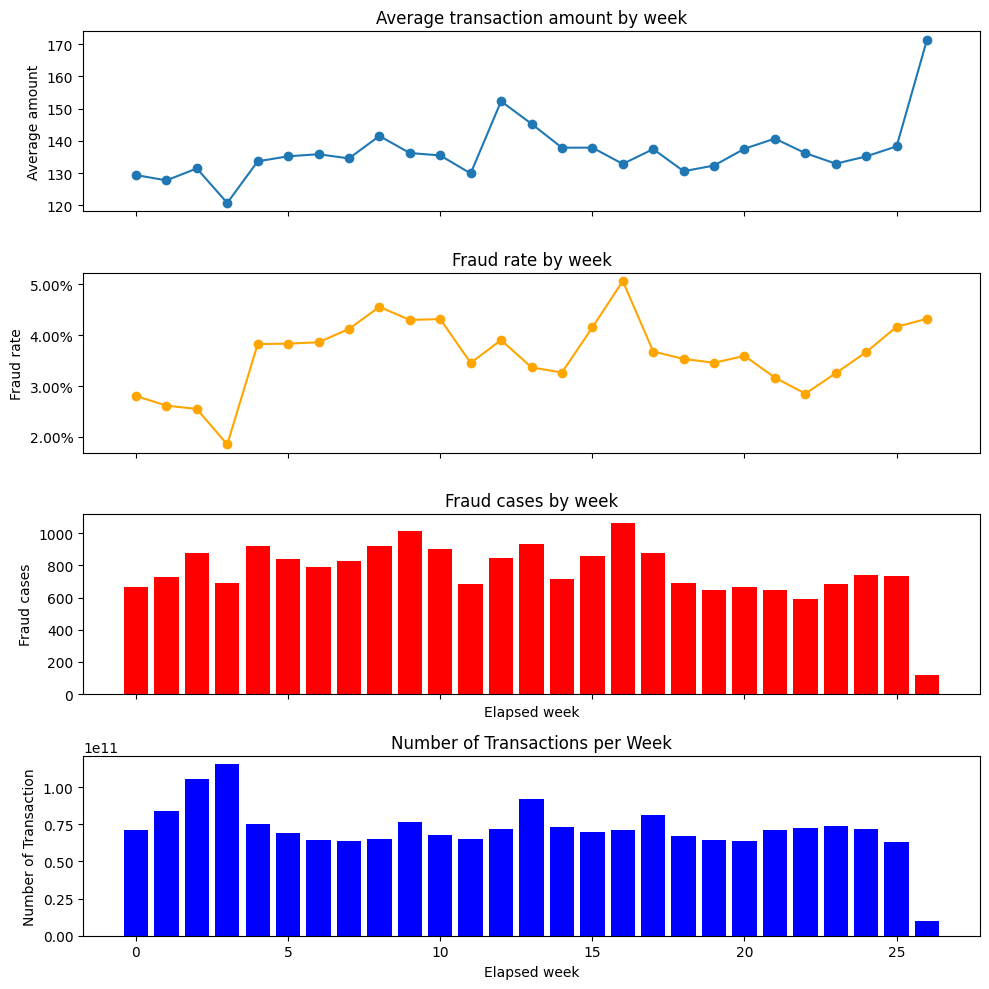

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(10, 10),
    sharex=True,
)

axes[0].plot(
    weekly_stats["week"],
    weekly_stats["average_transaction_amount"],
    marker="o",
)
axes[0].set_ylabel("Average amount")
axes[0].set_title("Average transaction amount by week")

axes[1].plot(
    weekly_stats["week"],
    weekly_stats["fraud_rate"],
    marker="o",
    color="orange",
)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_ylabel("Fraud rate")
axes[1].set_title("Fraud rate by week")

axes[2].bar(
    weekly_stats["week"],
    weekly_stats["fraud_count"],
    color="red",
)
axes[2].set_xlabel("Elapsed week")
axes[2].set_ylabel("Fraud cases")
axes[2].set_title("Fraud cases by week")


axes[3].bar(
    weekly_stats["week"],
    weekly_stats["num_transactions"],
    color="blue",
)
axes[3].set_xlabel("Elapsed week")
axes[3].set_ylabel("Number of Transaction")
axes[3].set_title("Number of Transactions per Week")


plt.tight_layout()
plt.show()